# Surface Ion Trap Optimization

A **surface ion trap** holds a single charged atom tens of micrometres above a chip. The chip carries flat metal electrodes, and a radio-frequency (RF) voltage on some of them creates an oscillating electric field. That field confines the ion, which then serves as a qubit. In this challenge you tune a five-wire trap design so that one $^{40}\text{Ca}^+$ ion is held stably, deeply and at a usable height [1].

This notebook gives you a working trap. It shows how to:

- describe the electrode cross-section as a PhotonForge port specification,
- compute its RF electric field with the mode solver,
- convert the field into the pseudopotential felt by the ion,
- read off the ion height, secular frequency, Mathieu stability parameter and trap depth,
- score the design against the challenge constraints.

You change four parameters: the RF electrode width, the electrode gap, the RF voltage amplitude and the RF drive frequency. Everything after the parameter cell runs unchanged.

**References**

1. Chiaverini, J., *et al*. "Surface-electrode architecture for ion-trap quantum information processing." *Quantum Information and Computation* 2005 5 (6), 419-439, doi: [10.26421/QIC5.6-1](https://doi.org/10.26421/QIC5.6-1).
2. House, M. G. "Analytic model for electrostatic fields in surface-electrode ion traps." *Physical Review A* 2008 78 (3), 033402, doi: [10.1103/PhysRevA.78.033402](https://doi.org/10.1103/PhysRevA.78.033402).
3. Leibfried, D., *et al*. "Quantum dynamics of single trapped ions." *Reviews of Modern Physics* 2003 75 (1), 281, doi: [10.1103/RevModPhys.75.281](https://doi.org/10.1103/RevModPhys.75.281).

## Physics primer

**Why RF.** A static electric potential cannot have a minimum in free space (Earnshaw's theorem), so static voltages alone cannot hold an ion. A Paul trap applies a voltage $V_{RF} \cos(\Omega t)$ to the RF electrodes instead. The ion then sees a field $\mathbf{E}_{RF}(\mathbf{r}) \cos(\Omega t)$, where $\mathbf{E}_{RF}$ is the field amplitude at position $\mathbf{r}$ and $\Omega = 2\pi f_{RF}$ is the angular drive frequency.

**Pseudopotential.** The ion follows the fast field with a small driven motion called micromotion. Averaged over one RF period, this motion pushes the ion towards weak field with an effective potential energy [3]

$$\Psi(\mathbf{r}) = \frac{q^2 \lvert \mathbf{E}_{RF}(\mathbf{r}) \rvert^2}{4 m \Omega^2},$$

where $q$ and $m$ are the ion charge and mass. The ion sits at the **RF null**, the point above the surface where $\mathbf{E}_{RF} = 0$. Its distance from the electrode surface is the **ion height**.

**Secular frequency.** Close to the null the pseudopotential is quadratic, $\Psi \approx \frac{1}{2} m \omega^2 r^2$, so the ion oscillates at the **secular frequency**

$$\omega = \sqrt{\frac{1}{m} \frac{\partial^2 \Psi}{\partial r^2}}.$$

This notebook fits a parabola to $\Psi$ around the null, separately along the two radial directions (lateral and vertical), and reports the lower of the two frequencies.

**Mathieu stability parameter.** The exact equation of motion is the Mathieu equation. Its parameter $q_M$ measures how hard the RF field drives the ion compared with the drive frequency. In the pseudopotential picture [3]

$$q_M = \frac{2\sqrt{2}\,\omega}{\Omega}.$$

The motion is stable for $q_M < 0.908$, and the pseudopotential picture is accurate for $q_M \lesssim 0.4$, which is the limit used in the score.

**Trap depth.** Far above the surface the field decays, so $\Psi$ rises from zero at the null to a maximum and then falls. The highest point the ion must climb to escape is a saddle point of $\Psi$; on the symmetry axis of this trap it lies directly above the ion. The **trap depth** is the pseudopotential at that saddle point. A deeper trap holds the ion longer against collisions with background gas.

**Scaling laws.** For a fixed geometry the field scales with the voltage, $\lvert \mathbf{E}_{RF} \rvert \propto V_{RF}$. The formulas above then give

$$\Psi \propto \frac{V_{RF}^2}{\Omega^2}, \qquad \omega \propto \frac{V_{RF}}{\Omega}, \qquad q_M \propto \frac{V_{RF}}{\Omega^2}.$$

The geometry sets the ion height and the shape of the field. Voltage and frequency set the strength of the confinement.

## Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import photonforge as pf
import tidy3d as td
from scipy.constants import atomic_mass, elementary_charge
from scipy.integrate import cumulative_trapezoid

# We raise the Tidy3D logging level to reduce output noise from the solve
# below. Warnings can flag real problems, so only suppress them once you have
# confirmed they are not relevant to your case.
td.config.logging.level = "ERROR"

## Design parameters

These four values are the design. Keep each one inside its range, so that every design you try stays physically valid. The starting values give a working trap that passes all constraints, with a modest depth.

In [2]:
# Width of each RF electrode, allowed range 20 to 200 (μm)
rf_width = 120.0

# Gap between neighbouring electrodes, allowed range 5 to 20 (μm)
gap = 10.0

# Peak RF voltage on the RF electrodes, allowed range 10 to 100 (V)
v_rf = 100

# RF drive frequency, allowed range 10e6 to 60e6 (Hz)
f_rf = 40.95e6

The rest of the trap is fixed. The electrodes are 2 µm thick gold on a 500 µm fused-silica wafer. The central ground electrode is 60 µm wide.

In [3]:
center_width = 60.0  # Width of the central ground electrode (μm)
metal_thickness = 2.0  # Thickness of the electrodes (μm)
substrate_thickness = 500.0  # Thickness of the fused-silica substrate (μm)
silica_permittivity = 3.8  # Relative permittivity of fused silica

ion_mass = 40 * atomic_mass  # Mass of a 40Ca+ ion (kg)
ion_charge = elementary_charge  # Charge of a 40Ca+ ion (C)

## Ion height estimate

House [2] derived the field of a surface trap in closed form, assuming the gaps between electrodes are infinitely thin. For the symmetric five-wire trap with central electrode width $a$ and RF electrode width $b$, the RF null sits at

$$h = \frac{1}{2}\sqrt{a\,(a + 2b)}.$$

Splitting each real gap equally between its two neighbours gives $a = w_{center} + g$ and $b = w_{RF} + g$. This estimate is a quick way to check whether a geometry lands in the allowed 50 to 100 µm window before you run anything.

In [4]:
# Effective electrode widths of the gapless model (μm)
a_eff = center_width + gap
b_eff = rf_width + gap

# Ion height from the closed-form gapless model (μm)
h_estimate = 0.5 * np.sqrt(a_eff * (a_eff + 2 * b_eff))
print(f"Estimated ion height: {h_estimate:.1f} μm")

Estimated ion height: 76.0 μm


## Technology

A PhotonForge [Technology](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.Technology.html) describes how each layout layer becomes a 3D structure. Here there is one layer, the electrode metal, extruded as a perfect electric conductor (PEC) on top of a fused-silica substrate. PEC is the right model for the field shape: at these frequencies the electrodes are equipotentials, and their resistance does not change where the field points or how strong it is.

PhotonForge's coordinate convention is used throughout: the trap axis runs along $x$, the electrodes sit side by side along $y$, and $z$ points up from the chip surface.

In [5]:
# Fused-silica substrate and perfectly conducting electrodes
silica = td.Medium(permittivity=silica_permittivity, name="Fused silica")

# One layout layer for the electrode metal
layers = {"METAL": pf.LayerSpec((1, 0), "Trap electrodes", "#b8a18b18", "\\")}

# Extrude the substrate under the whole chip, then the electrodes on top of it
extrusion_specs = [
    pf.ExtrusionSpec(pf.MaskSpec(), silica, (-substrate_thickness, 0)),
    pf.ExtrusionSpec(pf.MaskSpec((1, 0)), td.PEC, (0, metal_thickness)),
]

# Assemble the technology with an air background and make it the default
technology = pf.Technology(
    "Surface trap", "1.0", layers, extrusion_specs, {}, td.Medium()
)
pf.config.default_technology = technology

## Trap cross-section

The RF wavelength $c/f_{RF}$ is 5 to 30 m, while the trap is about 1 mm across. The field near the ion is therefore the same as the static field of the electrodes held at fixed voltages, and it does not change along the trap axis. A 2D calculation in the $yz$ cross-section is enough.

Seen along $x$, the electrodes form a multi-conductor transmission line, and PhotonForge describes a transmission-line cross-section with a [PortSpec](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.PortSpec.html). Its arguments are:

- `width` and `limits`: the size of the solver window, along $y$ and along $z$.
- `path_profiles`: one `(width, offset, layer)` entry per electrode, giving its width, the position of its centre along $y$, and its layer. The technology supplies the thickness and the material.
- `num_modes` and `target_neff`: the number of modes to find and the starting guess for their effective index, between 1 (air) and $\sqrt{3.8} \approx 1.95$ (fused silica).
- `voltage_path`: a line from an outer ground to an RF rail. Setting it marks the port as electrical.

The window is 8 mm wide and reaches 4 mm above the chip. Its edges are periodic, which is PhotonForge's default for this solver. The window edges still influence the field at the ion slightly, and this window is large enough that doubling it changes the trap depth by less than 1 %. Each outer ground reaches past the window edge, so through the periodic edges both outer grounds act as one ground conductor.

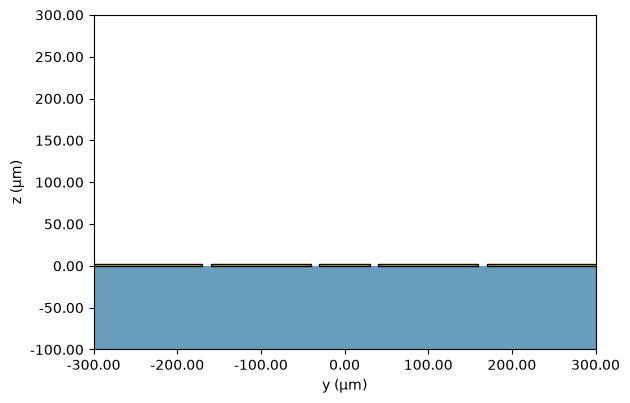

In [6]:
# Centre of each RF rail and inner edge of each outer ground along y (μm)
y_rf = center_width / 2 + gap + rf_width / 2
y_outer = center_width / 2 + 2 * gap + rf_width

# Half-width of the solver window and its height above the chip (μm)
half_width = 4000.0
top_height = 4000.0

# Width of each outer ground, reaching past the window edge (μm)
outer_width = half_width - y_outer + 100

# Cross-section of the five-wire trap
trap_spec = pf.PortSpec(
    description="Five-wire trap",
    width=2 * half_width,
    limits=(-substrate_thickness, top_height),
    num_modes=2,
    target_neff=1.5,
    path_profiles={
        "center": (center_width, 0, "METAL"),
        "rf0": (rf_width, y_rf, "METAL"),
        "rf1": (rf_width, -y_rf, "METAL"),
        "ground0": (outer_width, y_outer + outer_width / 2, "METAL"),
        "ground1": (outer_width, -y_outer - outer_width / 2, "METAL"),
    },
    voltage_path=[(y_outer, metal_thickness / 2), (y_rf, metal_thickness / 2)],
)

# Plot the cross-section around the trap
ax = pf.tidy3d_plot(trap_spec, frequency=f_rf)
ax.set_xlim(-300, 300)
ax.set_ylim(-100, 300)
ax.set_title("")
plt.show()

## RF field of the electrode cross-section

The port specification turns into a mode solver with `to_tidy3d`. Two settings are added before solving:

- **Mesh.** PhotonForge refines the mesh around the electrode edges and inside the gaps on its own. Away from the metal, it sizes cells from the wavelength, which here is metres long, so the region where the ion sits would get cells about 100 µm wide. A mesh override sets 1 µm cells over the region that holds the ion and its escape point.
- **Symmetry.** Both RF rails carry the same voltage, so the potential is mirror symmetric about $y = 0$ and only the half $y > 0$ is solved. The value `1` selects this symmetric case.

In [7]:
# Mode solver for the cross-section at the drive frequency
trap_solver = trap_spec.to_tidy3d([f_rf])

# Mesh the region of the ion and its escape point with 1 μm cells
ion_region = td.MeshOverrideStructure(
    geometry=td.Box.from_bounds((-1, -y_outer - 20, -10), (1, y_outer + 20, 300)),
    dl=(None, 1.0, 1.0),
)
grid_spec = trap_solver.simulation.grid_spec.updated_copy(
    override_structures=[ion_region]
)

# Solve only the half y > 0, using the mirror symmetry of the trap
simulation = trap_solver.simulation.updated_copy(
    symmetry=(0, 1, 0), grid_spec=grid_spec
)
trap_solver = trap_solver.updated_copy(simulation=simulation)

The left plot shows the whole solver window and its mesh: the cells are small near the electrodes and grow towards the window edges. The shaded half is the mirror image of the solved half. The right plot zooms into the gap between the central ground and an RF rail.

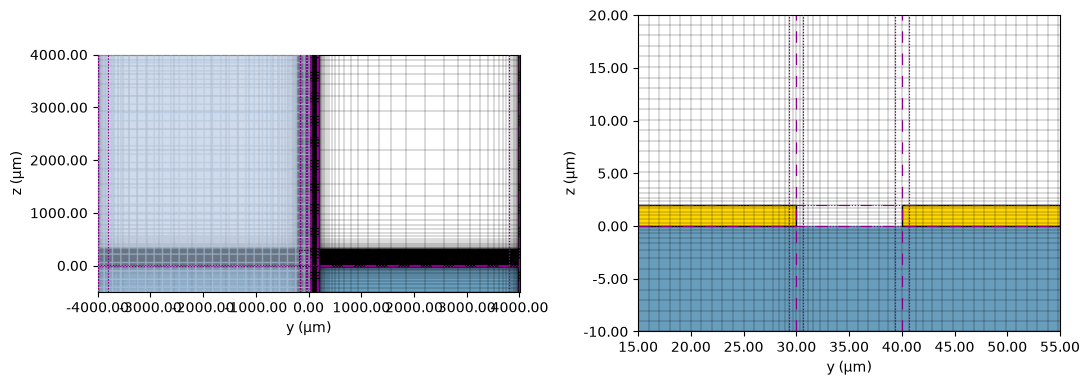

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), tight_layout=True)

# Whole solver window with its mesh
simulation.plot(x=0, ax=ax[0])
simulation.plot_grid(x=0, ax=ax[0])

# Close-up of the gap between the central ground and an RF rail
y_gap = center_width / 2 + gap / 2
simulation.plot(
    x=0, ax=ax[1], hlim=(y_gap - 2 * gap, y_gap + 2 * gap), vlim=(-gap, 2 * gap)
)
simulation.plot_grid(
    x=0, ax=ax[1], hlim=(y_gap - 2 * gap, y_gap + 2 * gap), vlim=(-gap, 2 * gap)
)
for a in ax:
    a.set_title("")
plt.show()

The next cell sends the cross-section to the cloud and waits for the result, which takes about a minute. PhotonForge caches each result, so running the cell again with the same geometry and frequency costs nothing. Changing only `v_rf` never needs a new solve, because the voltage enters only through the pseudopotential formula.

In [9]:
# Solve for the two quasi-TEM modes of the electrode cross-section
trap_solver = pf.port_modes(trap_solver, task_name="Surface trap")

# Effective index of each mode
print("Effective indices:", trap_solver.data.n_eff.values.ravel())

Uploading task 'Surface trap…'Progress: 0% -
Starting task 'Surface trap': https://tidy3d.simulation.cloud/workbench?taskId=mo-73f1fa57-f7e0-49f3-8de0-1d19cce43791
Progress: 100% 
Effective indices: [1.52747419 1.50433712]


The solver finds two **quasi-TEM** modes, whose transverse electric field is the static field of the electrodes for a particular set of voltages. There are two because the half cross-section holds three conductors, the RF rail, the central ground and the outer ground, and only voltage differences between them matter. Their effective indices lie between 1 and 1.95, since part of each mode's field runs in the substrate.

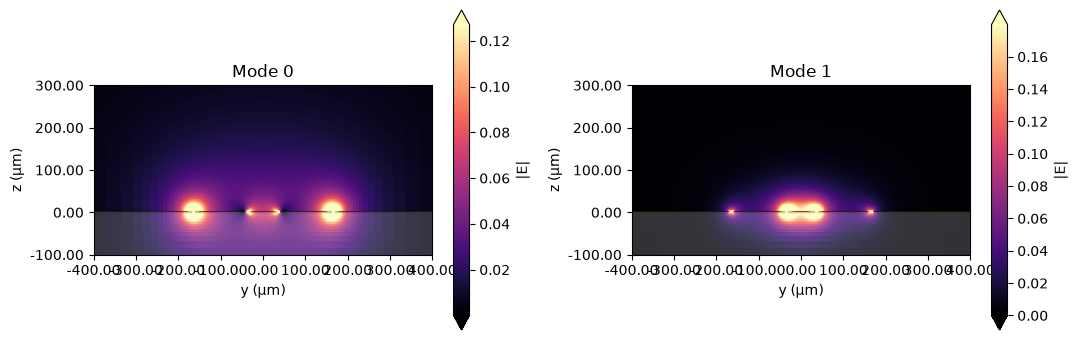

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), tight_layout=True)

# Electric field magnitude of each mode around the trap
for m in range(2):
    trap_solver.plot_field("E", "abs", mode_index=m, f=f_rf, ax=ax[m])
    ax[m].set_xlim(-400, 400)
    ax[m].set_ylim(-100, 300)
    ax[m].set_title(f"Mode {m}")
plt.show()

## Field with the RF rails at 1 V

Neither mode is the field of the actual trap, where the RF rails are at $V_{RF}$ and both grounds are at 0 V. Each mode is a different mix of conductor voltages. Because the field depends linearly on the voltages, the trap field is a weighted sum of the two modes, $\mathbf{E} = c_0 \mathbf{E}_0 + c_1 \mathbf{E}_1$.

The weights come from the conductor voltages. Along a line at mid-height of the electrodes, starting inside the outer ground, the potential relative to the outer ground is

$$\phi(y) = -\int_{y_{outer}}^{y} E_y \, dy'.$$

Its value at the centre of the RF rail and at the centre of the central ground gives a $2 \times 2$ matrix $M$ of conductor voltages in each mode. Solving $M \mathbf{c} = (1, 0)$ gives the weights that put the RF rail at 1 V and the central ground at 0 V.

In [11]:
# Mode fields on the cross-section at the drive frequency
fields = {
    component: trap_solver.data.field_components[component].isel(f=0).squeeze(drop=True)
    for component in ("Ey", "Ez")
}

# Line at mid-height of the electrodes, from inside the outer ground to the centre (μm)
y_line = np.linspace(y_outer + gap / 2, 0, 4001)

# Potential along the line in each mode, relative to the outer ground (V)
potentials = [
    -cumulative_trapezoid(
        fields["Ey"].isel(mode_index=m).interp(y=y_line, z=metal_thickness / 2).values,
        y_line,
        initial=0,
    )
    for m in range(2)
]

# Voltage of the RF rail (first row) and of the central ground (second row) in each mode
voltages = np.array(
    [
        [np.interp(y_rf, y_line[::-1], phi[::-1]) for phi in potentials],
        [phi[-1] for phi in potentials],
    ]
)

# Mode weights that put the RF rail at 1 V and the central ground at 0 V
weights = np.linalg.solve(voltages, [1.0, 0.0])

# Field of the trap per volt on the RF rails (V/μm)
e_unit = {
    component: sum(weights[m] * fields[component].isel(mode_index=m) for m in range(2))
    for component in fields
}

## Pseudopotential and trap metrics

The field per volt is sampled on a regular 0.5 µm grid around the trap, scaled by $V_{RF}$ and converted to the pseudopotential. The cell then finds:

- the **ion position**, the minimum of $\Psi$ on the symmetry axis $y = 0$,
- the **trap depth**, the highest value of $\Psi$ on the axis above the ion (the saddle point),
- the **secular frequencies**, from parabolas fitted to $\Psi$ within 3 µm of the ion along $y$ and along $z$,
- the **Mathieu parameter** $q_M$, from the higher of the two secular frequencies.

In [12]:
# Regular sampling grid around the trap (μm)
y_grid = np.arange(-150, 150.01, 0.5)
z_grid = np.arange(metal_thickness + 1, 350, 0.5)

# Squared field magnitude per volt on the grid, shape (y, z), in (V/μm)²
e2_unit = sum(
    np.abs(e_unit[component].interp(y=y_grid, z=z_grid).values) ** 2
    for component in e_unit
)

# Pseudopotential in J; the factor 1e12 converts (V/μm)² to (V/m)²
omega_rf = 2 * np.pi * f_rf
psi = ion_charge**2 * v_rf**2 * e2_unit * 1e12 / (4 * ion_mass * omega_rf**2)

# Pseudopotential in meV
psi_mev = psi / elementary_charge * 1e3

In [13]:
# Pseudopotential along the symmetry axis y = 0
i_axis = np.argmin(np.abs(y_grid))
psi_axis = psi[i_axis, :]

# Ion position: minimum of the pseudopotential on the axis
i_ion = np.argmin(psi_axis)
z_ion = z_grid[i_ion]
ion_height = z_ion - metal_thickness

# Escape point: maximum of the pseudopotential above the ion
i_saddle = i_ion + np.argmax(psi_axis[i_ion:])
trap_depth = psi_mev[i_axis, i_saddle] - psi_mev[i_axis, i_ion]

# Points within 3 μm of the ion for the parabola fits
fit_range = 3.0
near_z = np.abs(z_grid - z_ion) <= fit_range
near_y = np.abs(y_grid) <= fit_range

# Curvature of the pseudopotential along z and y (J/μm²)
curvature_z = 2 * np.polyfit(z_grid[near_z] - z_ion, psi_axis[near_z], 2)[0]
curvature_y = 2 * np.polyfit(y_grid[near_y], psi[near_y, i_ion], 2)[0]

# Secular angular frequencies; the factor 1e12 converts 1/μm² to 1/m²
omega_z = np.sqrt(curvature_z * 1e12 / ion_mass)
omega_y = np.sqrt(curvature_y * 1e12 / ion_mass)

# Radial secular frequency (Hz) and Mathieu parameter
f_secular = min(omega_y, omega_z) / (2 * np.pi)
q_mathieu = 2 * np.sqrt(2) * max(omega_y, omega_z) / omega_rf

print(f"Ion height above the electrodes: {ion_height:.1f} μm")
print(f"Secular frequency, lateral: {omega_y / 2 / np.pi / 1e6:.2f} MHz")
print(f"Secular frequency, vertical: {omega_z / 2 / np.pi / 1e6:.2f} MHz")
print(f"Mathieu parameter q: {q_mathieu:.3f}")
print(f"Trap depth: {trap_depth:.1f} meV")

Ion height above the electrodes: 75.5 μm
Secular frequency, lateral: 5.76 MHz
Secular frequency, vertical: 5.79 MHz
Mathieu parameter q: 0.400
Trap depth: 126.5 meV


The map shows the pseudopotential above the electrodes, with the colour scale capped at twice the trap depth. The ion sits in the dark spot at the RF null. The saddle point above it marks where an ion with enough energy escapes.

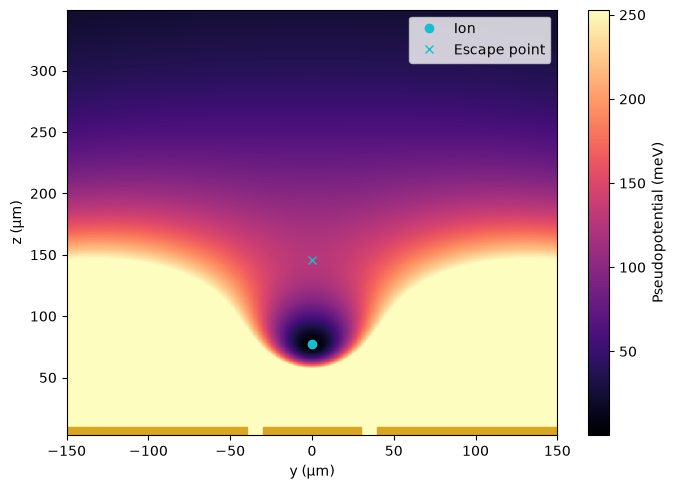

In [14]:
fig, ax = plt.subplots(figsize=(7, 5), tight_layout=True)

# Pseudopotential map in meV
mesh = ax.pcolormesh(
    y_grid, z_grid, psi_mev.T, vmax=2 * trap_depth, cmap="magma", shading="auto"
)
fig.colorbar(mesh, ax=ax, label="Pseudopotential (meV)")

# Ion position and escape point
ax.plot(0, z_ion, "o", color="tab:cyan", label="Ion")
ax.plot(0, z_grid[i_saddle], "x", color="tab:cyan", label="Escape point")

# Electrode positions along the bottom edge
for y0, y1 in [
    (-center_width / 2, center_width / 2),
    (center_width / 2 + gap, center_width / 2 + gap + rf_width),
    (-center_width / 2 - gap - rf_width, -center_width / 2 - gap),
]:
    ax.axvspan(y0, y1, ymax=0.02, color="goldenrod")
ax.set_xlabel("y (μm)")
ax.set_ylabel("z (μm)")
ax.set_xlim(y_grid[0], y_grid[-1])
ax.legend(loc="upper right")
plt.show()

## Score

The score function checks each constraint of the challenge. If all of them pass, the score is the trap depth in meV; otherwise it is zero. Ties on the leaderboard are broken by the lower RF voltage.

In [15]:
def trap_score(ion_height, f_secular, q_mathieu, v_rf, min_feature, trap_depth):
    # Pass or fail for every constraint of the challenge
    checks = {
        "Ion height 50 to 100 μm": 50 <= ion_height <= 100,
        "Radial secular frequency at least 1 MHz": f_secular >= 1e6,
        "Mathieu parameter q at most 0.4": q_mathieu <= 0.4,
        "Peak RF voltage at most 100 V": v_rf <= 100,
        "Minimum electrode feature or gap at least 5 μm": min_feature >= 5,
    }

    # Print the outcome of each check
    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}  {name}")

    # Trap depth if every constraint passes, zero otherwise
    return trap_depth if all(checks.values()) else 0.0


# Smallest drawn feature or gap of the layout (μm)
min_feature = min(center_width, rf_width, gap)

# Score of the current design
score = trap_score(ion_height, f_secular, q_mathieu, v_rf, min_feature, trap_depth)
print(f"\nScore: {score:.1f} meV at {v_rf:.0f} V")

PASS  Ion height 50 to 100 μm
PASS  Radial secular frequency at least 1 MHz
PASS  Mathieu parameter q at most 0.4
PASS  Peak RF voltage at most 100 V
PASS  Minimum electrode feature or gap at least 5 μm

Score: 126.5 meV at 100 V


## Where to go from here

- **Voltage and frequency first.** Use the scaling laws in the primer: for a fixed geometry, $\Psi \propto V_{RF}^2/\Omega^2$ and $q_M \propto V_{RF}/\Omega^2$. Work out which combination of $V_{RF}$ and $f_{RF}$ gives the deepest trap while keeping $q_M \le 0.4$ and $V_{RF} \le 100$ V. Changing `v_rf` reuses the cached field.
- **Then the geometry.** The RF width and the gap set the ion height and how much field reaches the ion per volt. Use the height estimate to stay inside the 50 to 100 µm window, then compare the trap depth of a few geometries at their best voltage and frequency.
- **Sweeps.** To compare many designs, put the cells from the trap cross-section to the score into a loop over a list of parameters. Every new geometry or frequency costs one cross-section solve, so plan your sweeps with the compute budget in mind.

# Trap depth optimisation: $V_{RF}$ vs $f_{RF}$

## Goal
Find the RF voltage $V_{RF}$ (10-100 V) and drive frequency $f_{RF}$ (10-60 MHz) that give the deepest trap for a $^{40}\text{Ca}^+$ ion, while keeping the pseudopotential approximation valid ($q_M \le 0.4$).

## Method
The electrode geometry is fixed (RF width = 120 µm, gap = 10 µm), so the field shape and the ion height (75.5 µm) do not change with $V_{RF}$ or $f_{RF}$. The field amplitude only scales with voltage, $|\mathbf{E}_{RF}| \propto V_{RF}$, so one mode-solver run at a reference point fixes the whole map:

| Quantity | Reference value at 60 V, 40 MHz |
|---|---|
| Trap depth | 47.8 meV |
| Lower (lateral) secular frequency, $\omega/2\pi$ | 3.54 MHz |
| Mathieu parameter $q_M$ | 0.251 |

The reference values are consistent: $q_M = 2\sqrt{2}\,\omega/\Omega = 2\sqrt{2}\,(3.54/40) \approx 0.250$.

## Scaling laws used

$$\Psi_{\text{depth}} = 47.8\ \text{meV}\left(\frac{V_{RF}}{60\ \text{V}}\right)^2\left(\frac{40\ \text{MHz}}{f_{RF}}\right)^2$$

$$q_M = 0.251\left(\frac{V_{RF}}{60\ \text{V}}\right)\left(\frac{40\ \text{MHz}}{f_{RF}}\right)^2$$

$$\frac{\omega}{2\pi} = 3.54\ \text{MHz}\left(\frac{V_{RF}}{60\ \text{V}}\right)\left(\frac{40\ \text{MHz}}{f_{RF}}\right)$$

## Why there is an optimum
Depth alone grows with higher $V_{RF}$ and lower $f_{RF}$, so it would point at the corner (100 V, 10 MHz). There $q_M$ is far above the limit, so the pseudopotential picture breaks down (and the ion is unstable for $q_M > 0.908$). The $q_M \le 0.4$ constraint is what bounds the problem.

At fixed $V_{RF}$, lowering $f_{RF}$ deepens the trap until $q_M$ reaches 0.4, so the optimum lies on the $q_M = 0.4$ boundary. Along that boundary $f_{RF}^2 \propto V_{RF}$, so depth $\propto V_{RF}^2/f_{RF}^2 \propto V_{RF}$. Depth therefore keeps rising with voltage, and the optimum is at the maximum voltage, 100 V.

## Result

$$f_{\text{opt}} = 40\ \text{MHz}\sqrt{\frac{0.251\,(100/60)}{0.4}} \approx 40.9\ \text{MHz}$$

| | $V_{RF}$ | $f_{RF}$ | Depth | $\omega/2\pi$ | $q_M$ |
|---|---|---|---|---|---|
| Reference | 60 V | 40 MHz | 47.8 meV | 3.54 MHz | 0.251 |
| **Optimum** | **100

Grid optimum:     V=100.0 V, f=40.95 MHz, depth=126.7 meV
Analytic optimum: V=100 V, f=40.91 MHz, depth=127.0 meV


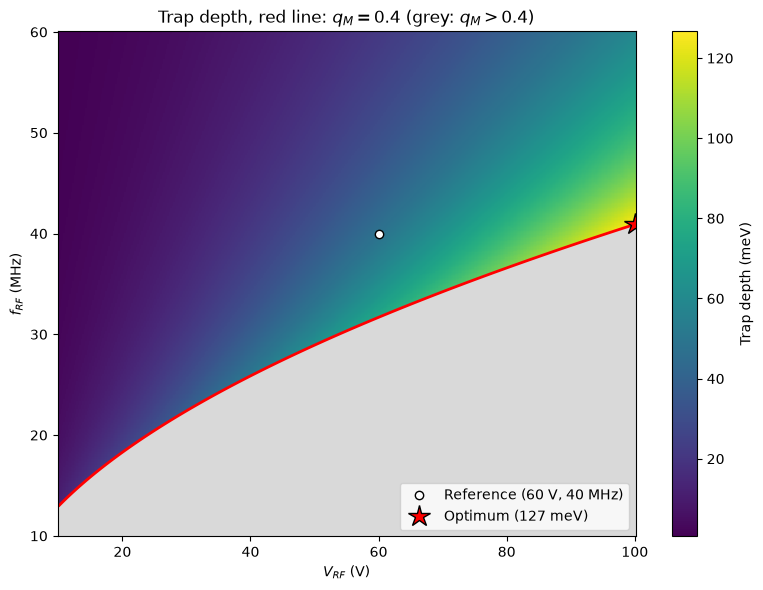

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Reference run (rf_width = 120 um, gap = 10 um)
V0, f0 = 60.0, 40e6
depth0 = 47.8          # meV
q0 = 0.251
w0 = 3.54e6            # Hz, lower secular frequency (omega/2pi)
Q_MAX = 0.4

V = np.linspace(10, 100, 400)
f = np.linspace(10e6, 60e6, 400)
VV, FF = np.meshgrid(V, f)

depth = depth0 * (VV / V0) ** 2 * (f0 / FF) ** 2
q = q0 * (VV / V0) * (f0 / FF) ** 2
w = w0 * (VV / V0) * (f0 / FF)

valid = q <= Q_MAX
depth_masked = np.where(valid, depth, np.nan)

# Numerical optimum on the grid, plus analytic check
i = np.nanargmax(depth_masked)
V_opt, f_opt, d_opt = VV.flat[i], FF.flat[i], depth.flat[i]
f_an = f0 * np.sqrt(q0 * (100 / V0) / Q_MAX)
d_an = depth0 * (100 / V0) ** 2 * (f0 / f_an) ** 2
print(f"Grid optimum:     V={V_opt:.1f} V, f={f_opt/1e6:.2f} MHz, depth={d_opt:.1f} meV")
print(f"Analytic optimum: V=100 V, f={f_an/1e6:.2f} MHz, depth={d_an:.1f} meV")

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_facecolor("0.85")  # grey = q > 0.4, excluded
pc = ax.pcolormesh(VV, FF / 1e6, depth_masked, shading="auto", cmap="viridis")
fig.colorbar(pc, ax=ax, label="Trap depth (meV)")
ax.contour(VV, FF / 1e6, q, levels=[Q_MAX], colors="red", linewidths=2)
ax.plot(V0, f0 / 1e6, "wo", mec="k", label="Reference (60 V, 40 MHz)")
ax.plot(100, f_an / 1e6, "r*", ms=16, mec="k",
        label=f"Optimum ({d_an:.0f} meV)")
ax.set_xlabel(r"$V_{RF}$ (V)")
ax.set_ylabel(r"$f_{RF}$ (MHz)")
ax.set_title(r"Trap depth, red line: $q_M = 0.4$ (grey: $q_M > 0.4$)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


# Geometry optimisation: RF width and gap

This notebook continues from the voltage and frequency step. It tunes the two geometry parameters, `rf_width` and `gap`, to maximise trap depth.

**The plan**

1. **Feasible region.** Use the House height estimate to keep only (rf_width, gap) pairs that land in the 50 to 100 µm window. This needs no solver.
2. **One solve per geometry.** Because the field only scales with voltage, one cross-section solve per geometry is enough. The scaling laws then give that geometry's best voltage and frequency.
3. **Coarse sweep, then refine.** Solve a small coarse grid, look at the trend, then solve a few points near the best one.
4. **Validate.** Re-solve the winner at its actual voltage and frequency and run the score.

**Scaling laws (fixed geometry)**

$$\Psi_{depth} \propto \frac{V^2}{f^2}, \qquad q_M \propto \frac{V}{f^2}, \qquad \omega \propto \frac{V}{f}$$

So with a reference solve at $(V_{ref}, f_{ref})$:

$$\text{depth}(V,f)=\text{depth}_{ref}\left(\tfrac{V}{V_{ref}}\right)^2\left(\tfrac{f_{ref}}{f}\right)^2,\qquad q(V,f)=q_{ref}\left(\tfrac{V}{V_{ref}}\right)\left(\tfrac{f_{ref}}{f}\right)^2$$

**Why overall size mostly drops out.** Depth and $q_M$ both scale as $1/h^2$ with the trap size, so at the pinned $V=100$ V and $q_M=0.4$ the reachable depth depends mostly on the *shape* of the geometry. The size mainly sets the frequency needed, $f \propto 1/h$. A small trap may need more than 60 MHz, which is why the code below has a frequency-capped branch. This is approximate (finite electrode thickness and gaps break it), so the sweep decides.

## Setup for the geometry sweep

The imports, technology, fixed trap parameters and `trap_score` are already defined in the starter cells above, so only the sweep settings are added here.

In [17]:
import json
import os

# Solver window
HALF_WIDTH = 4000.0   # um
TOP_HEIGHT = 4000.0   # um
Z_MESH_TOP = 400.0    # um, fine mesh up to here (covers the escape point)
Z_GRID_TOP = 390.0    # um, sampling grid up to here

# Reference point used for every solve. The field shape does not depend on
# frequency at these wavelengths, so we solve every geometry at the same F_SOLVE.
V_REF = 60.0
F_SOLVE = 40e6

# Challenge limits
Q_LIMIT = 0.4
Q_TARGET = 0.399     # small safety margin below the limit
V_MAX = 100.0
F_MIN, F_MAX = 10e6, 60e6

## Step 1: Feasible (rf_width, gap) region

The House estimate is $h = \tfrac12\sqrt{a(a+2b)}$ with $a = w_{center}+g$ and $b = w_{RF}+g$. The height depends on *both* parameters, so we filter the pairs jointly instead of choosing separate lists.

The estimate assumes infinitely thin gaps. It was about 0.5 µm off at (120, 10), but it may drift for large gaps, so we keep a margin (`H_LO`, `H_HI`) and confirm the true height from the solver later.

110 feasible pairs out of 133


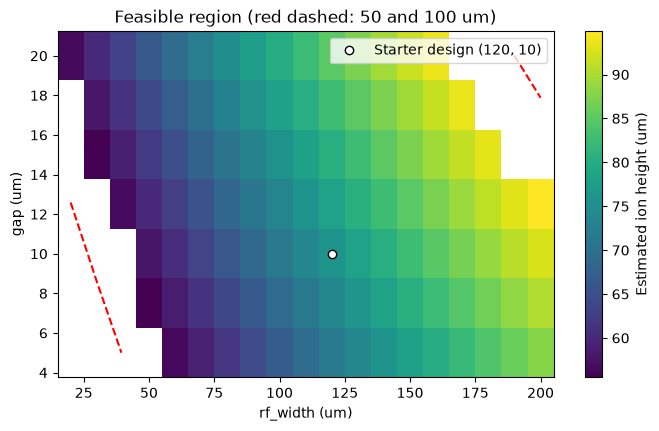

In [18]:
def house_height(rf_width, gap, center=center_width):
    a = center + gap
    b = rf_width + gap
    return 0.5 * np.sqrt(a * (a + 2 * b))

H_LO, H_HI = 55.0, 95.0   # margin inside the 50 to 100 um window

widths = np.arange(20, 201, 10.0)
gaps = np.array([5, 7.5, 10, 12.5, 15, 17.5, 20])
W, G = np.meshgrid(widths, gaps)
H = house_height(W, G)
feasible = (H >= H_LO) & (H <= H_HI)

feasible_pairs = {(float(w), float(g)) for w, g, ok in zip(W.ravel(), G.ravel(), feasible.ravel()) if ok}
print(f"{len(feasible_pairs)} feasible pairs out of {W.size}")

fig, ax = plt.subplots(figsize=(8, 4.5))
pc = ax.pcolormesh(W, G, np.where(feasible, H, np.nan), shading="auto", cmap="viridis")
ax.contour(W, G, H, levels=[50, 100], colors="red", linestyles="--")
fig.colorbar(pc, ax=ax, label="Estimated ion height (um)")
ax.plot(120, 10, "wo", mec="k", label="Starter design (120, 10)")
ax.set_xlabel("rf_width (um)")
ax.set_ylabel("gap (um)")
ax.set_title("Feasible region (red dashed: 50 and 100 um)")
ax.legend()
plt.show()

## Step 2: One solve per geometry

`solve_geometry` wraps the starter-notebook cells from the trap cross-section to the metrics into one function. It returns ion height, both secular frequencies, $q_M$ and trap depth at the given voltage and frequency.

- The mode solve runs at `f_solve`. The pseudopotential uses `f_rf`. For the sweep both equal `F_SOLVE`. For final validation set `f_solve = f_rf`.
- Each new geometry costs about one minute. PhotonForge caches identical solves.
- The sampling grid and fine mesh reach 390 to 400 µm so the escape point is covered for taller traps. The function warns if the saddle point sits at the edge of the grid.

In [19]:
def solve_geometry(rf_width, gap, v_rf=V_REF, f_rf=F_SOLVE, f_solve=F_SOLVE):
    # Electrode positions along y (um)
    y_rf = center_width / 2 + gap + rf_width / 2
    y_outer = center_width / 2 + 2 * gap + rf_width
    outer_width = HALF_WIDTH - y_outer + 100

    trap_spec = pf.PortSpec(
        description="Five-wire trap",
        width=2 * HALF_WIDTH,
        limits=(-substrate_thickness, TOP_HEIGHT),
        num_modes=2,
        target_neff=1.5,
        path_profiles={
            "center": (center_width, 0, "METAL"),
            "rf0": (rf_width, y_rf, "METAL"),
            "rf1": (rf_width, -y_rf, "METAL"),
            "ground0": (outer_width, y_outer + outer_width / 2, "METAL"),
            "ground1": (outer_width, -y_outer - outer_width / 2, "METAL"),
        },
        voltage_path=[(y_outer, metal_thickness / 2), (y_rf, metal_thickness / 2)],
    )

    # Mode solver with a fine mesh around the ion and the escape point, half-domain by symmetry
    solver = trap_spec.to_tidy3d([f_solve])
    ion_region = td.MeshOverrideStructure(
        geometry=td.Box.from_bounds((-1, -y_outer - 20, -10), (1, y_outer + 20, Z_MESH_TOP)),
        dl=(None, 1.0, 1.0),
    )
    grid_spec = solver.simulation.grid_spec.updated_copy(override_structures=[ion_region])
    simulation = solver.simulation.updated_copy(symmetry=(0, 1, 0), grid_spec=grid_spec)
    solver = solver.updated_copy(simulation=simulation)
    solver = pf.port_modes(solver, task_name=f"Trap w{rf_width:g} g{gap:g} f{f_solve/1e6:g}")

    # Combine the two modes into the field per volt on the RF rails
    fields = {
        c: solver.data.field_components[c].isel(f=0).squeeze(drop=True) for c in ("Ey", "Ez")
    }
    y_line = np.linspace(y_outer + gap / 2, 0, 4001)
    potentials = [
        -cumulative_trapezoid(
            fields["Ey"].isel(mode_index=m).interp(y=y_line, z=metal_thickness / 2).values,
            y_line,
            initial=0,
        )
        for m in range(2)
    ]
    voltages = np.array(
        [
            [np.interp(y_rf, y_line[::-1], phi[::-1]) for phi in potentials],
            [phi[-1] for phi in potentials],
        ]
    )
    weights = np.linalg.solve(voltages, [1.0, 0.0])
    e_unit = {
        c: sum(weights[m] * fields[c].isel(mode_index=m) for m in range(2)) for c in fields
    }

    # Pseudopotential on a regular grid
    y_grid = np.arange(-150, 150.01, 0.5)
    z_grid = np.arange(metal_thickness + 1, Z_GRID_TOP, 0.5)
    e2_unit = sum(
        np.abs(e_unit[c].interp(y=y_grid, z=z_grid).values) ** 2 for c in e_unit
    )
    omega_rf = 2 * np.pi * f_rf
    psi = ion_charge**2 * v_rf**2 * e2_unit * 1e12 / (4 * ion_mass * omega_rf**2)
    psi_mev = psi / elementary_charge * 1e3

    # Ion position, saddle point, secular frequencies, Mathieu parameter
    i_axis = np.argmin(np.abs(y_grid))
    psi_axis = psi[i_axis, :]
    i_ion = np.argmin(psi_axis)
    z_ion = z_grid[i_ion]
    ion_height = z_ion - metal_thickness
    i_saddle = i_ion + np.argmax(psi_axis[i_ion:])
    trap_depth = psi_mev[i_axis, i_saddle] - psi_mev[i_axis, i_ion]
    if i_saddle >= len(z_grid) - 3:
        print(f"WARNING w={rf_width}, g={gap}: saddle at grid edge, depth may be underestimated")

    fit_range = 3.0
    near_z = np.abs(z_grid - z_ion) <= fit_range
    near_y = np.abs(y_grid) <= fit_range
    curvature_z = 2 * np.polyfit(z_grid[near_z] - z_ion, psi_axis[near_z], 2)[0]
    curvature_y = 2 * np.polyfit(y_grid[near_y], psi[near_y, i_ion], 2)[0]
    omega_z = np.sqrt(curvature_z * 1e12 / ion_mass)
    omega_y = np.sqrt(curvature_y * 1e12 / ion_mass)

    return {
        "rf_width": float(rf_width), "gap": float(gap),
        "v_rf": float(v_rf), "f_rf": float(f_rf),
        "ion_height": float(ion_height),
        "f_secular": float(min(omega_y, omega_z) / (2 * np.pi)),
        "f_secular_lat": float(omega_y / (2 * np.pi)),
        "f_secular_vert": float(omega_z / (2 * np.pi)),
        "q": float(2 * np.sqrt(2) * max(omega_y, omega_z) / omega_rf),
        "depth": float(trap_depth),
        "house_estimate": float(house_height(rf_width, gap)),
    }

### Sanity check against the starter notebook

The starter design (120, 10) at 60 V and 40 MHz should give about 75.5 µm, 3.54 MHz lateral, q about 0.251 and depth about 47.8 meV. If it does not, fix the function before sweeping.

In [20]:
check = solve_geometry(120, 10, v_rf=60, f_rf=40e6)
for k, v in check.items():
    print(f"{k:16s} {v}")

Uploading task 'Trap w120 g10 f40…'Progress: 0% -
Starting task 'Trap w120 g10 f40': https://tidy3d.simulation.cloud/workbench?taskId=mo-28dcae18-133b-4a58-89b8-936258f68181
Progress: 100% 
rf_width         120.0
gap              10.0
v_rf             60.0
f_rf             40000000.0
ion_height       75.5
f_secular        3536481.062048593
f_secular_lat    3536481.062048593
f_secular_vert   3556820.9044409473
q                0.2515052180996263
depth            47.722791112755715
house_estimate   75.99342076785332


## Step 3: Best voltage and frequency for any solved geometry

Given one reference solve, this picks the best $(V, f)$:

- Prefer $V = 100$ V and the lowest frequency that keeps $q_M \le$ `Q_TARGET`.
- If that frequency would exceed 60 MHz, pin $f = 60$ MHz and lower the voltage until $q_M$ = `Q_TARGET`.
- Never go below 10 MHz.

It also reports the scaled secular frequency, which must stay at or above 1 MHz, and whether the solved ion height is inside the window.

In [21]:
def best_vf(res, q_target=Q_TARGET):
    V_ref, f_ref = res["v_rf"], res["f_rf"]
    q_ref, depth_ref = res["q"], res["depth"]

    f_q = f_ref * np.sqrt(q_ref * (V_MAX / V_ref) / q_target)   # lowest f allowed at 100 V
    if f_q <= F_MAX:
        V, f = V_MAX, max(f_q, F_MIN)
    else:
        f = F_MAX
        V = q_target * V_ref * (f / f_ref) ** 2 / q_ref
    depth = depth_ref * (V / V_ref) ** 2 * (f_ref / f) ** 2
    q = q_ref * (V / V_ref) * (f_ref / f) ** 2
    f_sec = res["f_secular"] * (V / V_ref) * (f_ref / f)
    ok = (
        50 <= res["ion_height"] <= 100
        and f_sec >= 1e6
        and q <= Q_LIMIT
        and V <= V_MAX
        and min(center_width, res["rf_width"], res["gap"]) >= 5
    )
    return {"V": V, "f": f, "depth": depth, "q": q, "f_sec": f_sec, "ok": ok}


# Test on the starter-notebook reference values (no solver needed)
test = {"rf_width": 120, "gap": 10, "v_rf": 60, "f_rf": 40e6,
        "ion_height": 75.5, "f_secular": 3.54e6, "q": 0.251, "depth": 47.8}
print(best_vf(test))   # expect roughly 100 V, ~40.9 MHz, ~127 meV

{'V': 100.0, 'f': np.float64(40957626.28877999), 'depth': np.float64(126.64143426294822), 'q': np.float64(0.39899999999999997), 'f_sec': np.float64(5762052.672096632), 'ok': True}


## Step 4: Coarse sweep

Pick a small grid from the feasible set. Results are saved to `geometry_results.json` after every solve, so you can stop and restart without repeating solves. `run_batch` skips anything already solved.

With the defaults this is about 12 solves, so roughly 12 minutes.

In [22]:
RESULTS_FILE = "geometry_results.json"
results = json.load(open(RESULTS_FILE)) if os.path.exists(RESULTS_FILE) else {}

def key(w, g):
    return f"{w:g}_{g:g}"

def run_batch(pairs):
    todo = [(w, g) for w, g in pairs if key(w, g) not in results]
    print(f"{len(todo)} new solves (about {len(todo)} min), {len(pairs) - len(todo)} already done")
    for i, (w, g) in enumerate(todo, 1):
        print(f"[{i}/{len(todo)}] rf_width={w:g}, gap={g:g} ...", end=" ", flush=True)
        results[key(w, g)] = solve_geometry(w, g)
        json.dump(results, open(RESULTS_FILE, "w"), indent=1)
        print(f"height {results[key(w, g)]['ion_height']:.1f} um, depth {results[key(w, g)]['depth']:.1f} meV")

coarse_gaps = [5, 10, 20]
coarse_widths = [40, 80, 120, 160, 200]
coarse = [(float(w), float(g)) for g in coarse_gaps for w in coarse_widths if (float(w), float(g)) in feasible_pairs]
print(coarse)

[(80.0, 5.0), (120.0, 5.0), (160.0, 5.0), (200.0, 5.0), (80.0, 10.0), (120.0, 10.0), (160.0, 10.0), (200.0, 10.0), (40.0, 20.0), (80.0, 20.0), (120.0, 20.0), (160.0, 20.0)]


In [23]:
run_batch(coarse)

12 new solves (about 12 min), 0 already done
Uploading task 'Trap w80 g5 f40…'rting…
Starting task 'Trap w80 g5 f40': https://tidy3d.simulation.cloud/workbench?taskId=mo-bfd497b5-1eb9-42ec-a3d4-e2b0112712e9
Progress: 100% 
height 62.0 um, depth 58.8 meV
Uploading task 'Trap w120 g5 f40…'rting…
Starting task 'Trap w120 g5 f40': https://tidy3d.simulation.cloud/workbench?taskId=mo-cc25820c-5a3e-4f86-a3ba-9d53b010fd2c
Progress: 100% 
height 71.5 um, depth 54.3 meV
Uploading task 'Trap w160 g5 f40…'Progress: 0% -
Starting task 'Trap w160 g5 f40': https://tidy3d.simulation.cloud/workbench?taskId=mo-c24afc91-0c68-4dca-ac2d-c21e733ba22e
Progress: 100% 
height 80.0 um, depth 47.2 meV
Uploading task 'Trap w200 g5 f40…'Progress: 0% -
Starting task 'Trap w200 g5 f40': https://tidy3d.simulation.cloud/workbench?taskId=mo-6d979830-84eb-4b26-8f44-88e03ccd515b
Progress: 100% 
height 87.5 um, depth 40.7 meV
Uploading task 'Trap w80 g10 f40…'Progress: 0% -
Starting task 'Trap w80 g10 f40': https://tidy3d

## Step 5: Compare geometries

Each solved geometry is converted to its own best voltage and frequency, then ranked by depth.

In [24]:
def summarize():
    rows = []
    for res in results.values():
        b = best_vf(res)
        rows.append({**res, **{"V_best": b["V"], "f_best": b["f"], "depth_best": b["depth"],
                               "q_best": b["q"], "f_sec_best": b["f_sec"], "ok": b["ok"]}})
    rows.sort(key=lambda r: r["depth_best"] if r["ok"] else -1, reverse=True)
    return rows

rows = summarize()
print(f"{'width':>6} {'gap':>5} {'h(um)':>6} {'est':>6} {'V':>6} {'f(MHz)':>7} {'q':>6} {'fsec':>5} {'depth':>7}  ok")
for r in rows:
    print(f"{r['rf_width']:6.0f} {r['gap']:5.1f} {r['ion_height']:6.1f} {r['house_estimate']:6.1f} "
          f"{r['V_best']:6.1f} {r['f_best']/1e6:7.2f} {r['q_best']:6.3f} {r['f_sec_best']/1e6:5.2f} "
          f"{r['depth_best']:7.1f}  {r['ok']}")

 width   gap  h(um)    est      V  f(MHz)      q  fsec   depth  ok
   200  10.0   92.0   92.6  100.0   33.71  0.399  4.74   143.1  True
   200   5.0   87.5   87.9  100.0   35.63  0.399  4.97   142.5  True
   160   5.0   80.0   80.1  100.0   39.10  0.399  5.48   137.3  True
   160  10.0   84.0   84.7  100.0   37.16  0.399  5.19   135.2  True
   160  20.0   92.5   93.8  100.0   33.52  0.399  4.70   134.1  True
   120   5.0   71.5   71.5  100.0   43.55  0.399  6.10   127.3  True
   120  10.0   75.5   76.0  100.0   41.00  0.399  5.75   126.2  True
   120  20.0   83.5   84.9  100.0   36.84  0.399  5.14   123.2  True
    80  10.0   66.0   66.1  100.0   45.34  0.399  6.39   110.7  True
    80   5.0   62.0   61.8  100.0   48.66  0.399  6.84   110.5  True
    80  20.0   74.0   74.8  100.0   40.06  0.399  5.62   110.2  True
    40  20.0   62.5   63.2  100.0   43.03  0.399  6.07    83.4  True


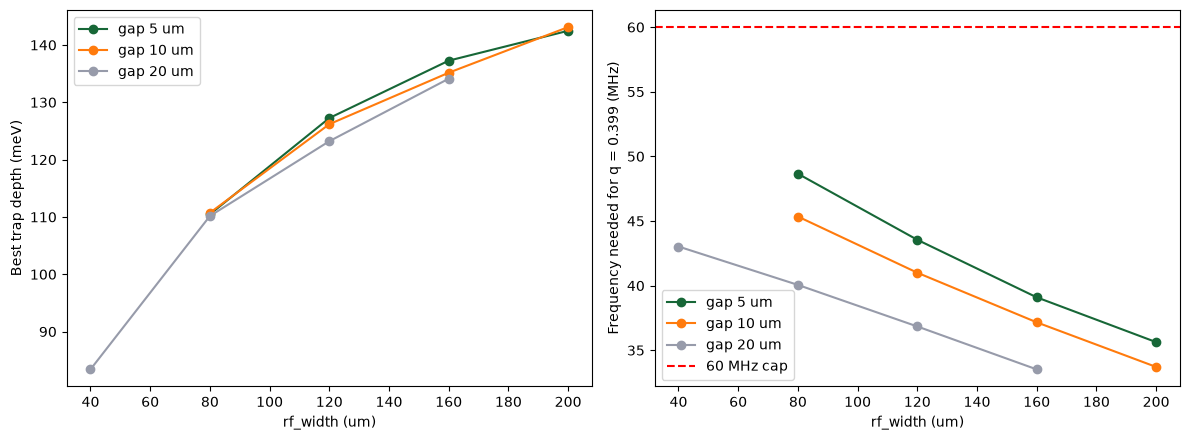

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), tight_layout=True)
for g in sorted({r["gap"] for r in rows}):
    pts = sorted([r for r in rows if r["gap"] == g], key=lambda r: r["rf_width"])
    ax[0].plot([p["rf_width"] for p in pts], [p["depth_best"] for p in pts], "o-", label=f"gap {g:g} um")
    ax[1].plot([p["rf_width"] for p in pts], [p["f_best"] / 1e6 for p in pts], "o-", label=f"gap {g:g} um")
ax[0].set_xlabel("rf_width (um)"); ax[0].set_ylabel("Best trap depth (meV)"); ax[0].legend()
ax[1].axhline(60, color="red", ls="--", label="60 MHz cap")
ax[1].set_xlabel("rf_width (um)"); ax[1].set_ylabel("Frequency needed for q = 0.399 (MHz)"); ax[1].legend()
plt.show()

## Step 6: Refine around the best point

Read the plot above first. If depth rises towards one edge (for example wider electrodes or a smaller gap), extend the grid in that direction. The cell below proposes neighbours of the current best geometry. Edit `refine` by hand if the trend suggests a different direction.

In [26]:
best = rows[0]
bw, bg = best["rf_width"], best["gap"]
print(f"Current best: rf_width={bw:g}, gap={bg:g}, depth={best['depth_best']:.1f} meV")

refine = []
for dw in (-20, -10, 0, 10, 20):
    for dg in (-2.5, 0, 2.5):
        w, g = bw + dw, bg + dg
        ok_range = 20 <= w <= 200 and 5 <= g <= 20
        if ok_range and H_LO - 5 <= house_height(w, g) <= H_HI + 5 and (dw, dg) != (0, 0):
            refine.append((float(w), float(g)))
print(len(refine), "refinement candidates:", refine)

Current best: rf_width=200, gap=10, depth=143.1 meV
8 refinement candidates: [(180.0, 7.5), (180.0, 10.0), (180.0, 12.5), (190.0, 7.5), (190.0, 10.0), (190.0, 12.5), (200.0, 7.5), (200.0, 12.5)]


In [27]:
# Run only the points you want. Trim `refine` first if you want to save compute.
run_batch(refine)
rows = summarize()
for r in rows[:5]:
    print(f"w={r['rf_width']:g}, g={r['gap']:g}: {r['depth_best']:.1f} meV at {r['V_best']:.1f} V, {r['f_best']/1e6:.2f} MHz")

8 new solves (about 8 min), 0 already done
Uploading task 'Trap w180 g7.5 f40…'ting…
Starting task 'Trap w180 g7.5 f40': https://tidy3d.simulation.cloud/workbench?taskId=mo-1042f712-b2fc-417c-8992-a3d2a1af3a76
Progress: 100% 
height 86.0 um, depth 41.6 meV
Uploading task 'Trap w180 g10 f40…'ting…
Starting task 'Trap w180 g10 f40': https://tidy3d.simulation.cloud/workbench?taskId=mo-a4875840-c85d-44a8-9f2f-abd6e69f1bc2
Progress: 100% 
height 88.0 um, depth 39.2 meV
Uploading task 'Trap w180 g12.5 f40…'Progress: 0% -
Starting task 'Trap w180 g12.5 f40': https://tidy3d.simulation.cloud/workbench?taskId=mo-c6d942b5-f8ea-4dd0-8dbd-cd9a5946234e
Progress: 100% 
height 90.5 um, depth 37.3 meV
Uploading task 'Trap w190 g7.5 f40…'Progress: 0% -
Starting task 'Trap w190 g7.5 f40': https://tidy3d.simulation.cloud/workbench?taskId=mo-d2789692-a57c-49d8-b720-a7ae5461087a
Progress: 100% 
height 88.0 um, depth 40.1 meV
Uploading task 'Trap w190 g10 f40…'Progress: 0% -
Starting task 'Trap w190 g10 f40'

## Step 7: Validate the winner with a real solve

Re-solve the best geometry at its actual voltage and frequency (`f_solve = f_rf`) and run the challenge score. The frequency is rounded up to the next 10 kHz so rounding cannot push $q_M$ over the limit.

In [28]:
# trap_score is defined in the starter notebook above
best = rows[0]
w_final, g_final = best["rf_width"], best["gap"]
V_final = round(best["V_best"], 2)
f_final = np.ceil(best["f_best"] / 1e4) * 1e4

final = solve_geometry(w_final, g_final, v_rf=V_final, f_rf=f_final, f_solve=f_final)
print(f"\nDesign: rf_width={w_final:g} um, gap={g_final:g} um, V={V_final} V, f={f_final/1e6:.2f} MHz")
print(f"Ion height {final['ion_height']:.1f} um, q = {final['q']:.4f}, "
      f"secular {final['f_secular']/1e6:.2f} MHz, depth {final['depth']:.1f} meV (predicted {best['depth_best']:.1f})\n")

score = trap_score(final["ion_height"], final["f_secular"], final["q"], V_final,
                   min(center_width, w_final, g_final), final["depth"])
print(f"\nScore: {score:.1f} meV at {V_final:.0f} V")

Uploading task 'Trap w190 g7.5 f35.29…'Progress: 0% -
Starting task 'Trap w190 g7.5 f35.29': https://tidy3d.simulation.cloud/workbench?taskId=mo-54a77395-6d91-40aa-94d0-06b3a84d323e
Progress: 100% 

Design: rf_width=190 um, gap=7.5 um, V=100.0 V, f=35.29 MHz
Ion height 88.0 um, q = 0.3989, secular 4.97 MHz, depth 143.2 meV (predicted 143.3)

PASS  Ion height 50 to 100 μm
PASS  Radial secular frequency at least 1 MHz
PASS  Mathieu parameter q at most 0.4
PASS  Peak RF voltage at most 100 V
PASS  Minimum electrode feature or gap at least 5 μm

Score: 143.2 meV at 100 V


## Notes

- **Prediction vs validation.** The validated depth should match the predicted depth closely. A larger gap means the scaling assumption (or the frequency independence of the field) needs a second look.
- **Frequency cap.** If your best designs sit at 60 MHz with V below 100 V, the geometry is frequency-limited. Taller traps (larger ion height) need a lower frequency for the same $q_M$.
- **Tie-break.** Ties on the leaderboard go to the lower RF voltage, so among equal depths prefer the design with the smaller V.
- **Compute budget.** About one solve per geometry. The coarse sweep is about 12 and refinement about 10 to 14, so roughly 25 solves in total.